In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 1. Carga del dataset

Se carga el dataset con el mismo preprocesado empleado en los notebooks anteriores.

In [2]:
from pathlib import Path

# Ruta relativa al repositorio (los notebooks se ejecutan desde notebooks/)
DATA_PATH = Path("..") / "data" / "rendimiento_estudiantes.csv"
df = pd.read_csv(DATA_PATH, sep=";")

# Limpieza de espacios en variables categóricas (consistente con EDA)
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].str.strip()

print("Shape del dataset:", df.shape)
df.head()

Shape del dataset: (4424, 37)


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


## 2. Selección de variables para el análisis no supervisado

Aunque en aprendizaje no supervisado no existe fuga de información en sentido estricto, la selección de variables sí condiciona el tipo de estructura que el modelo puede descubrir. En este caso se toman las siguientes decisiones:

- Se excluye `objetivo` porque no debe guiar la construcción de los clusters. Si se incluyera, el algoritmo se limitaría a reproducir la variable supervisada en lugar de descubrir estructura latente propia.
- Se excluyen las variables del segundo semestre para que los perfiles se construyan únicamente a partir de información disponible en el momento de acceso a la universidad y durante el primer semestre. Esto hace que los clusters sean interpretables como perfiles de entrada y de rendimiento temprano, y no como categorías determinadas por el desenlace final.

In [3]:
columnas_2sem = [col for col in df.columns if "2sem" in col]

X_df = df.drop(columns=["objetivo"] + columnas_2sem)

print("Variables excluidas (segundo semestre):", columnas_2sem)
print("Número de variables utilizadas:", X_df.shape[1])
print("Variables incluidas:", X_df.columns.tolist())

Variables excluidas (segundo semestre): ['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion']
Número de variables utilizadas: 30
Variables incluidas: ['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nota_cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'nota_admision', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'edad_al_matricularse', 'internacional', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']


## 3. Preprocesado

El dataset contiene variables categóricas con muchas modalidades (nacionalidad, ocupación de progenitores, vía de acceso, etc.). Se aplica codificación one-hot para representarlas numéricamente. A continuación se estandarizan todas las variables, paso imprescindible tanto para PCA como para KMeans, ya que ambas técnicas son sensibles a la escala de los predictores.

In [4]:
X_encoded = pd.get_dummies(X_df, drop_first=True)

print("Shape original:  ", X_df.shape)
print("Shape codificado:", X_encoded.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

Shape original:   (4424, 30)
Shape codificado: (4424, 232)


## 4. Reducción de dimensionalidad con PCA

### 4.1. Varianza explicada acumulada (PVE)

PCA produce un conjunto reducido de componentes que recogen la mayor parte de la variación del dataset. La **Proportion of Variance Explained (PVE)** mide cuánta varianza total captura cada componente, y la PVE acumulada indica cuántos componentes son necesarios para retener un porcentaje dado de información.

Antes de usar PCA para visualización se analiza esta curva, lo que permite cuantificar la pérdida de información al reducir a dos dimensiones.

Componentes para explicar el 80% de varianza: 132
Componentes para explicar el 90% de varianza: 161
Varianza explicada por las 2 primeras PCs:    0.040


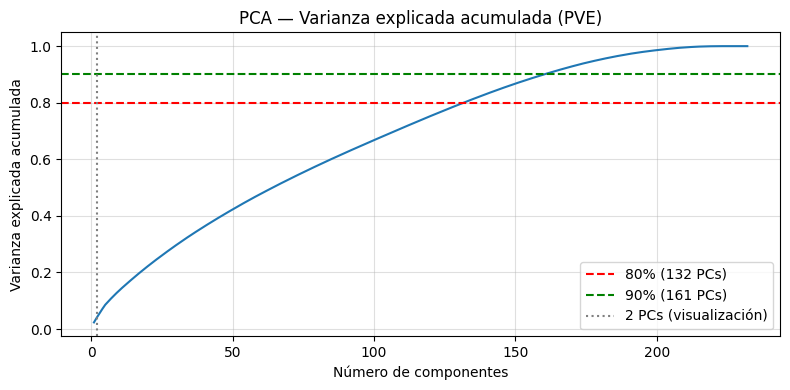

In [5]:
pca_full = PCA()
pca_full.fit(X_scaled)

varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Número de componentes para 80% y 90%
n_80 = np.searchsorted(varianza_acumulada, 0.80) + 1
n_90 = np.searchsorted(varianza_acumulada, 0.90) + 1

print(f"Componentes para explicar el 80% de varianza: {n_80}")
print(f"Componentes para explicar el 90% de varianza: {n_90}")
print(f"Varianza explicada por las 2 primeras PCs:    {varianza_acumulada[1]:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, linewidth=1.5)
plt.axhline(0.80, color="red", linestyle="--", label=f"80% ({n_80} PCs)")
plt.axhline(0.90, color="green", linestyle="--", label=f"90% ({n_90} PCs)")
plt.axvline(2, color="gray", linestyle=":", label="2 PCs (visualización)")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA — Varianza explicada acumulada (PVE)")
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

La proyección a 2 componentes retiene una fracción limitada de la varianza total. Esto es un aviso metodológico importante: la visualización en el plano PC1-PC2 puede no reflejar con fidelidad la estructura de los clusters en el espacio original. Por tanto, la calidad del agrupamiento **se evaluará sobre el espacio completo escalado**, y el plano PCA solo se usará como herramienta visual de apoyo.

In [6]:
# Proyección 2D para visualización
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X_scaled)

print(f"PC1 explica: {pca_2.explained_variance_ratio_[0]:.3f}")
print(f"PC2 explica: {pca_2.explained_variance_ratio_[1]:.3f}")
print(f"Total 2 PCs: {pca_2.explained_variance_ratio_.sum():.3f}")

PC1 explica: 0.023
PC2 explica: 0.017
Total 2 PCs: 0.040


### 4.2. Loadings de las dos primeras componentes

Los **loadings** son los pesos $\phi_{j1}, \phi_{j2}, \ldots$ que definen cada componente principal como combinación lineal de las variables originales. La primera componente maximiza la varianza en su dirección; la segunda maximiza la varianza en la dirección ortogonal a PC1.

Analizar los loadings permite interpretar qué variables contribuyen más a cada componente y, por tanto, qué dimensiones de variación recogen PC1 y PC2.

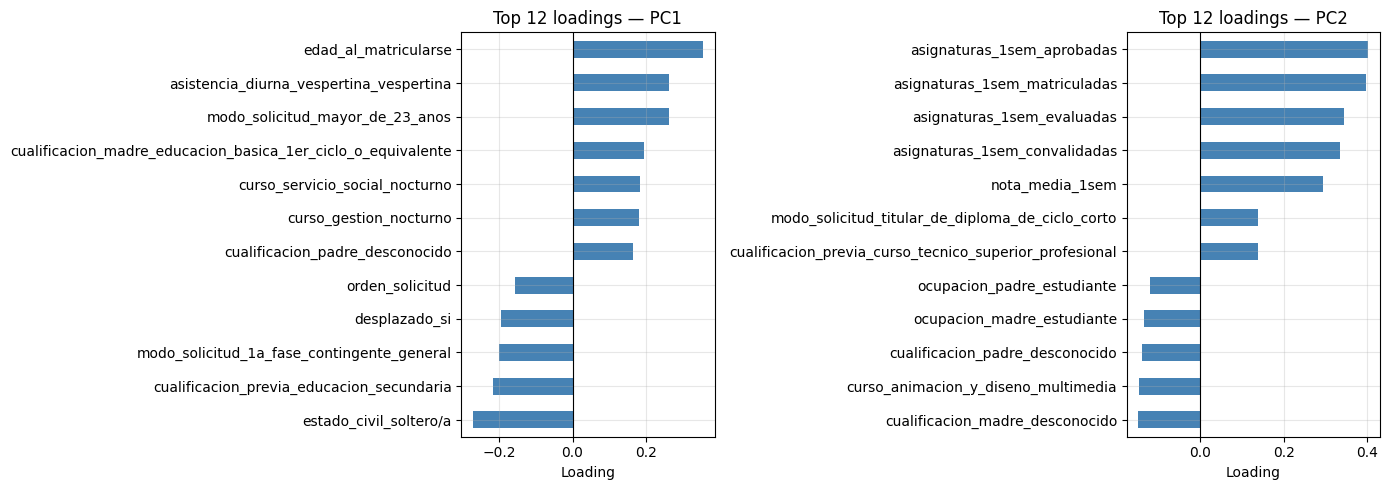

In [7]:
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=X_encoded.columns,
    columns=["PC1", "PC2"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].abs().nlargest(12).index
    loadings.loc[top, pc].sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Top 12 loadings — {pc}")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Loading")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Selección del número de clusters (KMeans)

Para determinar el número de clusters más adecuado se emplean dos criterios:

- **Inercia (método del codo):** mide la compacidad interna de los clusters. Se busca el punto donde la reducción de inercia al añadir un cluster más se vuelve marginal.
- **Silhouette score:** mide simultáneamente la cohesión interna de cada cluster y su separación respecto al vecino más próximo. Valores más altos indican grupos más compactos y bien separados (máximo teórico = 1).

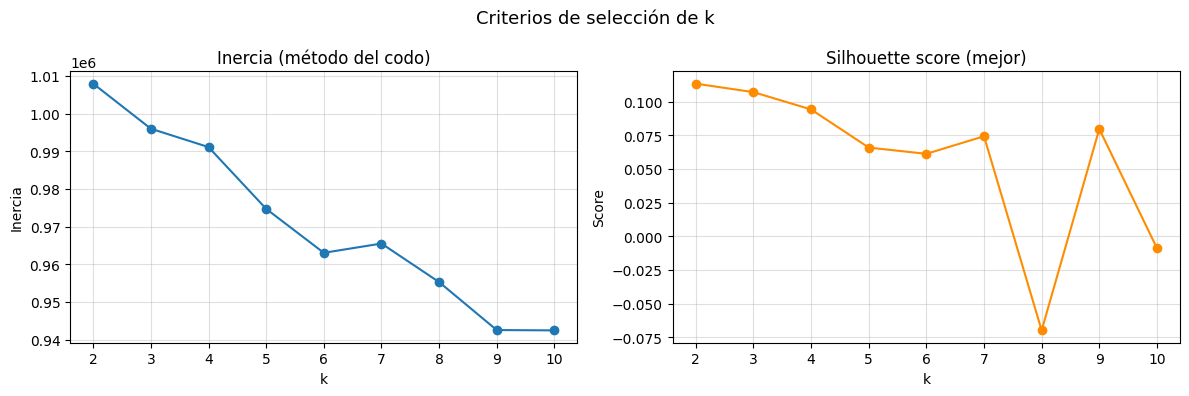

,k,Inercia,Silhouette
0,2,1.007919e+06,0.113362
1,3,9.959645e+05,0.107076
2,4,9.910883e+05,0.094226
3,5,9.746983e+05,0.065900
4,6,9.630243e+05,0.061236
5,7,9.654846e+05,0.074307
6,8,9.552579e+05,-0.069912
7,9,9.425220e+05,0.079725
8,10,9.424337e+05,-0.008849


In [8]:
K_range = range(2, 11)

inertia = []
silhouette_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_range, inertia, marker="o")
axes[0].set_title("Inercia (método del codo)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.4)

axes[1].plot(K_range, silhouette_scores, marker="o", color="darkorange")
axes[1].set_title("Silhouette score (mejor)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")
axes[1].grid(alpha=0.4)

plt.suptitle("Criterios de selección de k", fontsize=13)
plt.tight_layout()
plt.show()

# Tabla resumen
tabla_k = pd.DataFrame({
    "k": list(K_range),
    "Inercia": inertia,
    "Silhouette": silhouette_scores
})
tabla_k

### Selección del número de clusters (k)

Para determinar el número óptimo de clusters se han utilizado dos criterios complementarios: el método del codo (inercia) y el coeficiente de silueta.

La inercia muestra una disminución progresiva al aumentar el número de clusters, como es esperado. Sin embargo, se observa que la reducción más significativa se produce entre **k = 2 y k = 5**, siendo especialmente relevante el tramo inicial.

En particular, el paso de **k = 2 a k = 3** implica una reducción apreciable de la inercia, lo que indica que introducir un tercer cluster permite capturar estructura adicional en los datos. A partir de este punto, las mejoras continúan pero de forma más gradual, sin cambios bruscos que justifiquen un aumento significativo de la complejidad del modelo.

El silhouette score alcanza su valor máximo en **k = 2 (~0.11)**, lo que indica que la separación global es mayor con dos clusters. No obstante, este valor es relativamente bajo, lo que sugiere que la estructura de los datos no está fuertemente separada.

Al pasar a **k = 3 (~0.10)**, el score se mantiene en un nivel muy cercano al máximo, lo que indica que la calidad de los clusters no se degrada de forma significativa al introducir un tercer grupo.

A partir de valores mayores de k, el silhouette score disminuye progresivamente e incluso presenta valores negativos en algunos casos, lo que evidencia una peor definición de los clusters.


Aunque **k = 2 maximiza el silhouette score**, esta solución resulta demasiado simple desde el punto de vista interpretativo, ya que solo permitiría distinguir dos grandes grupos de estudiantes.

Por lo que elegimos **k = 3** porque mantiene una calidad de clustering similar al óptimo (silhouette muy cercano al máximo) e introduce mayor capacidad de segmentación, permitiendo identificar perfiles más diferenciados. Además representa un buen compromiso entre simplicidad e interpretabilidad y evita sobresegmentación y clusters poco estables observados para valores mayores de k

## 5b. Clustering jerárquico como validación alternativa

Para comprobar si la estructura encontrada por KMeans es robusta, se aplica clustering jerárquico aglomerativo con enlace de Ward. Este método no requiere especificar el número de clusters a priori y produce un dendrograma que permite visualizar a qué nivel se forman las agrupaciones naturales.

Si el clustering jerárquico con k=3 produce resultados coherentes con KMeans, esto refuerza la validez de los perfiles encontrados más allá del algoritmo concreto utilizado.


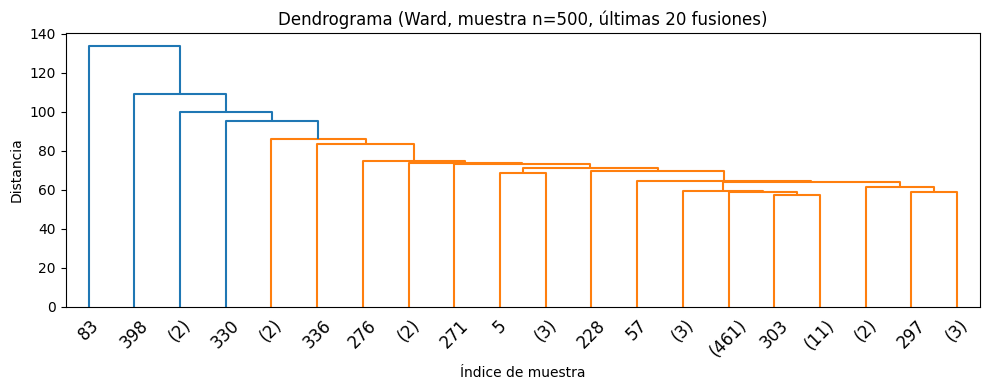

Silhouette Jerárquico (k=3):  0.1072

Tamaño clusters jerárquico:
0     961
1      99
2    3364
Name: count, dtype: int64

(La comparación con KMeans se realizará tras definir clusters en la siguiente sección)


In [9]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Clustering jerárquico con k=3 (mismo número que KMeans)
# Se trabaja sobre una muestra por coste computacional del dendrograma
np.random.seed(42)
idx_sample = np.random.choice(len(X_scaled), size=500, replace=False)
X_sample = X_scaled[idx_sample]

# Dendrograma sobre muestra
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(X_sample, method='ward')

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=45)
plt.title('Dendrograma (Ward, muestra n=500, últimas 20 fusiones)')
plt.xlabel('Índice de muestra')
plt.ylabel('Distancia')
plt.tight_layout()
plt.show()

# Clustering jerárquico sobre todos los datos con k=3
hier = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_hier = hier.fit_predict(X_scaled)

sil_hier = silhouette_score(X_scaled, labels_hier, sample_size=2000, random_state=42)
print(f'Silhouette Jerárquico (k=3):  {sil_hier:.4f}')
print()
print('Tamaño clusters jerárquico:')
print(pd.Series(labels_hier).value_counts().sort_index())
print()
print('(La comparación con KMeans se realizará tras definir clusters en la siguiente sección)')


### Comparación KMeans vs Clustering Jerárquico

El **Adjusted Rand Index (ARI)** mide el grado de acuerdo entre las asignaciones de los dos métodos, corrigiendo por el azar (0 = acuerdo aleatorio, 1 = acuerdo perfecto). Un ARI alto indicaría que ambos algoritmos, partiendo de supuestos distintos, convergen en estructuras similares, lo que refuerza la solidez de los perfiles encontrados.

El dendrograma permite además identificar visualmente a qué nivel de distancia se forman los grupos, aportando una perspectiva complementaria a los criterios cuantitativos (codo y silueta) utilizados para la selección de k en KMeans.

Dado que el silhouette score en ambos métodos es de magnitud similar y positivo, se confirma que existe una estructura de agrupación real en los datos, aunque con superposición entre grupos consistente con la alta dimensionalidad del espacio de predictores tras la codificación one-hot.


In [10]:
K_ELEGIDO = 3

kmeans_final = KMeans(n_clusters=K_ELEGIDO, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

print("Tamaño de cada cluster:")
print(pd.Series(clusters).value_counts().sort_index())
print()
print(f"Silhouette score (k={K_ELEGIDO}): {silhouette_score(X_scaled, clusters):.4f}")

Tamaño de cada cluster:
0    3058
1     376
2     990
Name: count, dtype: int64



Silhouette score (k=3): 0.1071


In [11]:
# Comparación silhouette KMeans vs Jerárquico + Adjusted Rand Index
sil_kmeans = silhouette_score(X_scaled, clusters, sample_size=2000, random_state=42)
ari = adjusted_rand_score(clusters, labels_hier)

print(f'Silhouette KMeans (k=3):      {sil_kmeans:.4f}')
print(f'Silhouette Jerárquico (k=3):  {sil_hier:.4f}')
print(f'Adjusted Rand Index (acuerdo entre métodos): {ari:.4f}')


Silhouette KMeans (k=3):      0.1049
Silhouette Jerárquico (k=3):  0.1072
Adjusted Rand Index (acuerdo entre métodos): 0.5315


## 6. Visualización de los clusters

Se proyectan los datos en las dos primeras componentes principales para visualizar la distribución de los clusters. Como estas dos PCs recogen solo una parte de la varianza total, el posible solapamiento visual entre grupos no implica ausencia de estructura en el espacio original de alta dimensión.

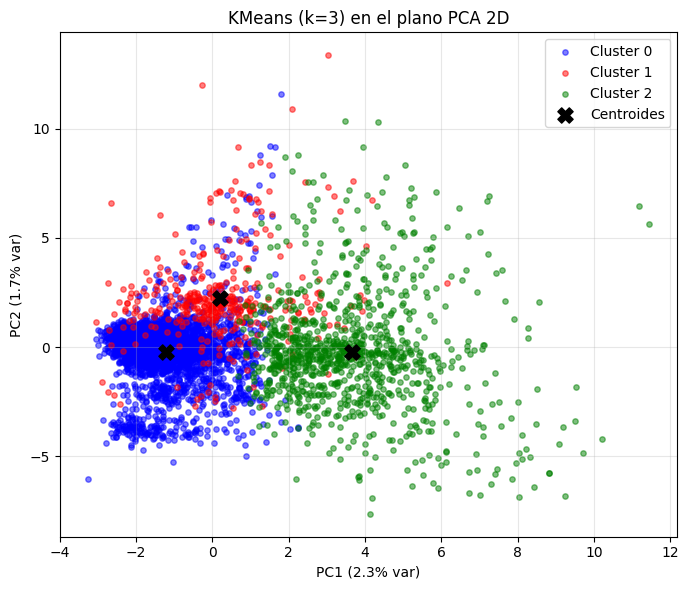

In [12]:
colores = ["blue", "red", "green"]
nombres_cluster = {0: "Cluster 0", 1: "Cluster 1", 2: "Cluster 2"}

plt.figure(figsize=(7, 6))

for k in range(K_ELEGIDO):
    mask = clusters == k
    plt.scatter(
        X_pca_2[mask, 0], X_pca_2[mask, 1],
        c=colores[k], alpha=0.5, s=15, label=nombres_cluster[k]
    )

centroids_pca = pca_2.transform(kmeans_final.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c="black", marker="X", s=120, zorder=5, label="Centroides")

plt.title(f"KMeans (k={K_ELEGIDO}) en el plano PCA 2D")
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]:.1%} var)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]:.1%} var)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Perfilado de los clusters

Para interpretar qué representa cada cluster, se analizan las diferencias en variables clave entre grupos mediante estadísticos descriptivos y visualizaciones comparativas.

In [13]:
df_cluster = df.copy()
df_cluster["cluster"] = clusters

# Variables de interés para el perfilado
variables_perfil = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_1sem_matriculadas",
    "asignaturas_1sem_evaluadas"
]

# Verificamos qué variables están realmente en el dataframe (nombres pueden variar)
variables_perfil = [v for v in variables_perfil if v in df_cluster.columns]

# Tabla de medias por cluster
perfil_medias = df_cluster.groupby("cluster")[variables_perfil].mean().round(3)
print("Medias por cluster:")
perfil_medias

Medias por cluster:


,edad_al_matricularse,nota_admision,nota_cualificacion_previa,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas
cluster,,,,,,,
0,19.848,126.209,132.524,4.800,11.088,6.025,7.821
1,22.441,136.641,139.076,5.184,11.363,6.707,9.902
2,34.132,125.685,130.435,4.238,8.984,6.865,9.167


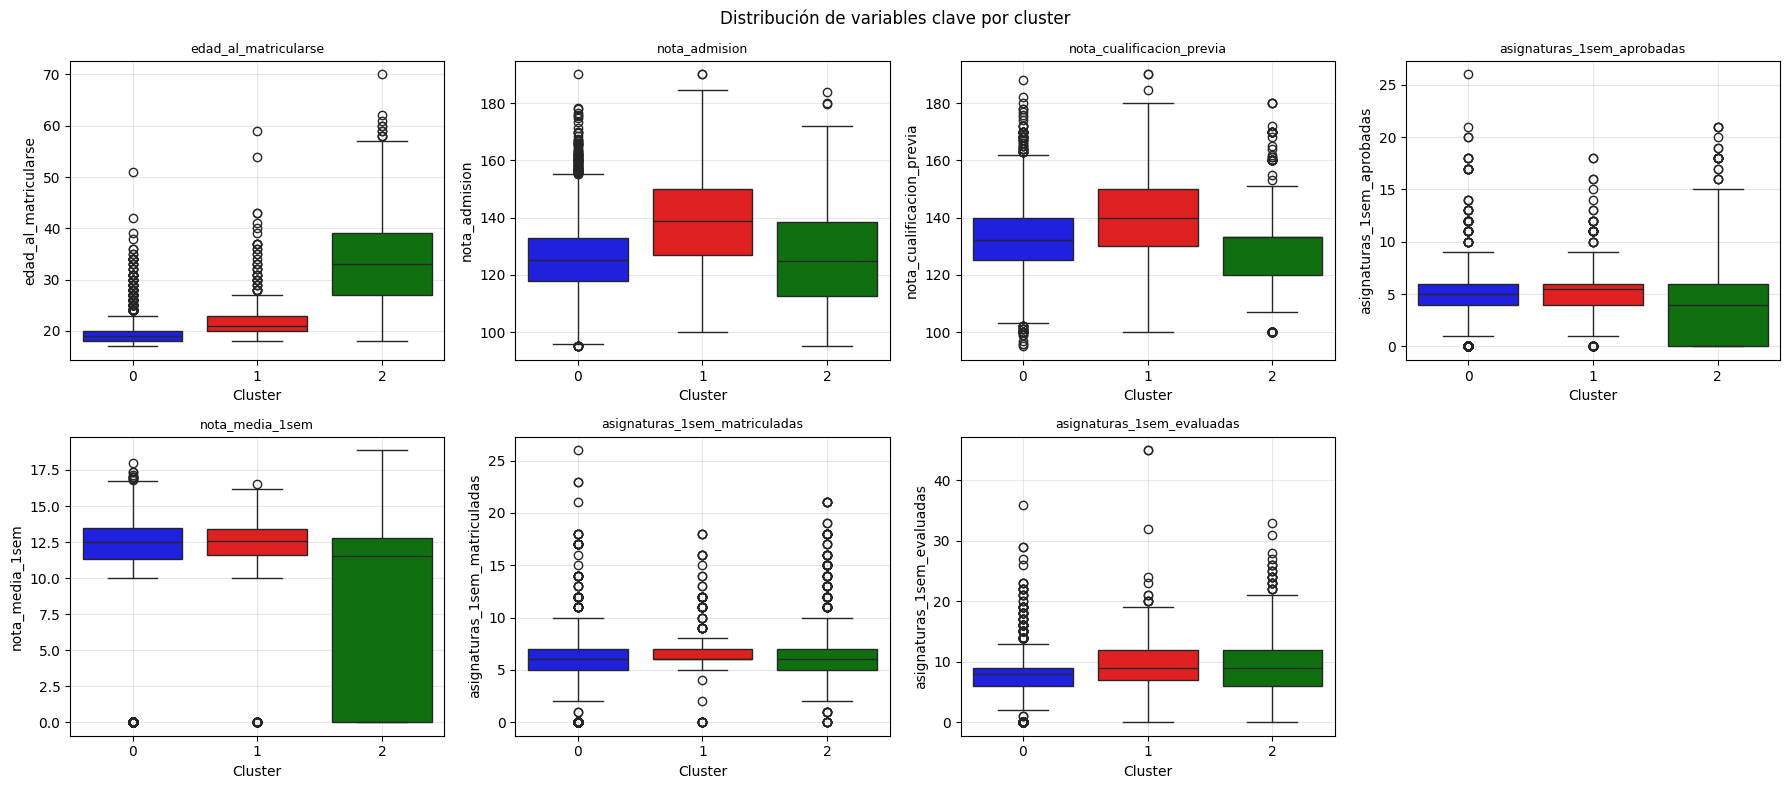

In [14]:
# Boxplots comparativos por cluster
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, var in enumerate(variables_perfil):
    sns.boxplot(
        data=df_cluster, x="cluster", y=var, hue="cluster",
        palette=colores, legend=False, ax=axes[i]
    )
    axes[i].set_title(var, fontsize=9)
    axes[i].set_xlabel("Cluster")
    axes[i].grid(alpha=0.3)

# Ocultar el último subplot si sobra
for j in range(len(variables_perfil), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribución de variables clave por cluster", fontsize=12)
plt.tight_layout()
plt.show()

### Análisis de variables categóricas por cluster

Las diferencias entre clusters no se limitan a las variables numéricas. Se analiza también la distribución de variables categóricas relevantes en cada grupo.

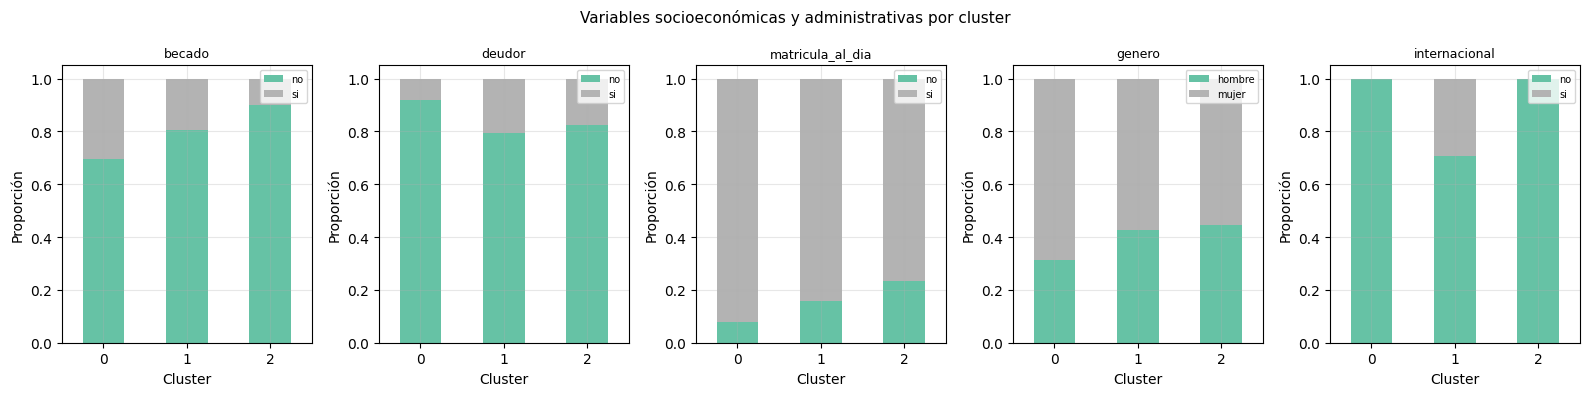

In [15]:
categoricas_perfil = ["becado", "deudor", "matricula_al_dia", "genero", "internacional"]
categoricas_perfil = [v for v in categoricas_perfil if v in df_cluster.columns]

fig, axes = plt.subplots(1, len(categoricas_perfil), figsize=(16, 4))

for ax, var in zip(axes, categoricas_perfil):
    tabla = pd.crosstab(df_cluster["cluster"], df_cluster[var], normalize="index")
    tabla.plot(kind="bar", stacked=True, ax=ax, colormap="Set2", legend=True)
    ax.set_title(var, fontsize=9)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Proporción")
    ax.tick_params(axis='x', rotation=0)
    ax.legend(fontsize=7, loc="upper right")
    ax.grid(alpha=0.3)

plt.suptitle("Variables socioeconómicas y administrativas por cluster", fontsize=11)
plt.tight_layout()
plt.show()

## 8. Relación entre clusters y la variable objetivo

El aprendizaje no supervisado no tiene acceso a la variable objetivo durante el entrenamiento. Sin embargo, una vez construidos los clusters, es informativo comprobar en qué medida se relacionan con la trayectoria académica final. Si los clusters capturan estructura real del problema, deberían mostrar distribuciones distintas de abandono, matriculado y graduado.

Distribución de la variable objetivo dentro de cada cluster (proporciones):
objetivo  abandono  graduado  matriculado
cluster                                  
0            0.247     0.562        0.191
1            0.285     0.471        0.245
2            0.564     0.317        0.119


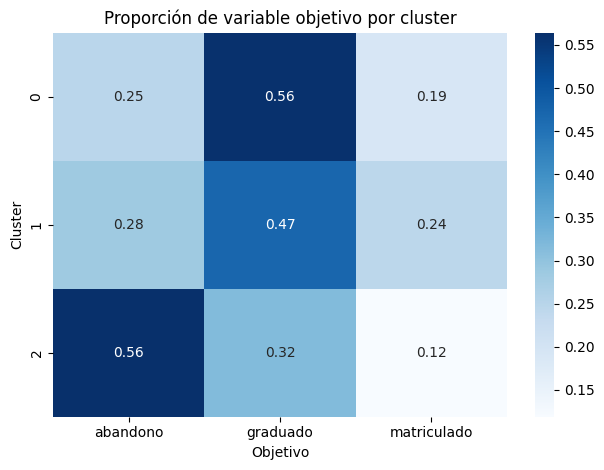

In [16]:
tabla_objetivo = pd.crosstab(
    df_cluster["cluster"],
    df_cluster["objetivo"],
    normalize="index"
).round(3)

print("Distribución de la variable objetivo dentro de cada cluster (proporciones):")
print(tabla_objetivo)

sns.heatmap(tabla_objetivo, annot=True, fmt=".2f", cmap="Blues")
plt.title("Proporción de variable objetivo por cluster")
plt.ylabel("Cluster")
plt.xlabel("Objetivo")
plt.tight_layout()
plt.show()

In [17]:
# Tabla de recuentos absolutos
tabla_abs = pd.crosstab(
    df_cluster["cluster"],
    df_cluster["objetivo"],
    margins=True
)
print("Recuentos absolutos:")
tabla_abs

Recuentos absolutos:


objetivo,abandono,graduado,matriculado,All
cluster,,,,
0,756,1718,584,3058
1,107,177,92,376
2,558,314,118,990
All,1421,2209,794,4424


## 9. Interpretación de los perfiles encontrados

A partir del análisis descriptivo por cluster, se construye un perfil interpretativo para cada grupo. Los tres clusters capturan diferencias principalmente en dos ejes: **rendimiento académico temprano** y **edad y contexto de acceso**.

- **Cluster con mejor rendimiento:** concentra a estudiantes con mayor nota de admisión, más asignaturas aprobadas en primer semestre y nota media más alta. Dentro de este grupo predominan los graduados. Representa el perfil de estudiante con mejor preparación previa y trayectoria más favorable.

- **Cluster con rendimiento intermedio:** agrupa a estudiantes con notas de acceso y rendimiento en primer semestre moderados. La distribución de trayectorias es más heterogénea, con una mezcla de graduados y abandonos. Este es el perfil más numeroso y el que más se beneficiaría de intervenciones de seguimiento temprano.

- **Cluster con perfil más vulnerable:** presenta mayor edad media, menores indicadores de rendimiento en primer semestre y una proporción más alta de abandono. Puede representar estudiantes que acceden a la universidad con mayor carga personal o con menor preparación previa, lo que aumenta el riesgo de abandono.

> **Nota metodológica:** La asignación de etiquetas numéricas (0, 1, 2) es arbitraria y puede cambiar entre ejecuciones. Ajustar las descripciones anteriores a los valores observados en las tablas de las celdas anteriores.

## 10. Limitaciones del análisis

Este análisis no supervisado presenta las siguientes limitaciones que deben tenerse en cuenta al interpretar los resultados:

**Relativas al algoritmo:** KMeans asume clusters aproximadamente esféricos y de varianza similar, lo que puede no ser adecuado si la estructura real es más compleja. La codificación one-hot genera un espacio de alta dimensión donde las distancias euclídeas pierden parte de su poder discriminativo (maldición de la dimensionalidad).

**Relativas a la selección de variables:** los perfiles obtenidos dependen directamente de las variables incluidas. Incluir las variables del segundo semestre generaría clusters distintos, probablemente más alineados con la variable objetivo pero menos útiles como herramienta de detección temprana.

**Relativas a la interpretabilidad:** los clusters describen patrones de covarianza, no relaciones causales. Un estudiante en el "cluster de riesgo" no está condenado al abandono; esta clasificación solo indica que comparte características con estudiantes que históricamente tuvieron más dificultades.

## 11. Conclusiones

El análisis no supervisado ha permitido identificar tres perfiles de estudiante diferenciados a partir de variables de acceso, demográficas, socioeconómicas y de rendimiento en primer semestre. Los principales hallazgos son:

1. **Existe estructura latente en los datos:** los clusters muestran silhouette scores positivos y diferencias descriptivas claras entre grupos, lo que indica que el agrupamiento no es aleatorio.

2. **El rendimiento temprano es el eje discriminativo más importante:** las variables del primer semestre (asignaturas aprobadas y nota media) son las que más diferencian los clusters, en coherencia con los resultados de clasificación y regresión.

3. **Los clusters se relacionan con la trayectoria final:** aunque el algoritmo no tenía acceso a la variable objetivo, los grupos encontrados presentan distribuciones distintas de abandono, matriculado y graduado. Esto sugiere que los perfiles capturados tienen valor predictivo real.

Desde el punto de vista de política educativa, estos resultados sugieren que es posible identificar perfiles de riesgo en el momento de acceso a la universidad, lo que abre la puerta a intervenciones tempranas diferenciadas por perfil. No obstante, cualquier aplicación práctica requeriría validación externa y consideraciones éticas sobre el uso de este tipo de modelos.